# Kenya Food & Nutrition Security Analysis

## Background

Food insecurity remains an important public health and socioeconomic
challenge in Kenya however access to food is not only about whether
food is available but the ability of households to afford food, differences
in food prices across markets, poverty and nutritional outcomes can all
influence food security.

In this project i will use publicly available kenyan data to explore
differences in food affordability and nutrition related vulnerability
across the country.

The aim is to identify patterns in the data and determine which areas
may require greater attention from nutrition and food security
programmes.

## Main Research Question

How does food affordability vary across Kenya and what relationship
does it have with food and nutrition vulnerability?

## Objectives

1. Explore food price trends across Kenyan markets.
2. Examine differences in food poverty across counties.
3. Investigate the relationship between food affordability and
   socioeconomic vulnerability.
4. Identify counties that appear particularly vulnerable to food
   insecurity.
5. Develop data driven recommendations that could support nutrition
   and food-security interventions.

In [1]:
import pandas as pd

# Load the food price dataset
food_prices = pd.read_csv("kenya food security data.csv")

# Display the first 5 rows
food_prices.head()

,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_maize_fao,c_maize_fao,inflation_maize_fao,trust_maize_fao,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
0,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-01-01,2007,...,22.05,22.98,NaN,9.5,0.52,0.54,0.50,0.52,NaN,8.9
1,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-02-01,2007,...,22.19,22.26,NaN,9.5,0.52,0.54,0.50,0.51,NaN,8.9
2,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-03-01,2007,...,20.99,20.99,NaN,9.5,0.51,0.53,0.49,0.52,NaN,8.9
3,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-04-01,2007,...,20.08,20.08,NaN,9.5,0.52,0.54,0.50,0.51,NaN,8.9
4,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-05-01,2007,...,19.22,19.22,NaN,9.5,0.51,0.53,0.49,0.49,NaN,8.9


In [2]:
#check the data set
food_prices.shape

(55926, 46)

In [3]:
#column names
food_prices.columns.tolist()

['ISO3',
 'country',
 'adm1_name',
 'adm2_name',
 'mkt_name',
 'lat',
 'lon',
 'geo_id',
 'price_date',
 'year',
 'month',
 'currency',
 'components',
 'start_dense_data',
 'last_survey_point',
 'data_coverage',
 'data_coverage_recent',
 'index_confidence_score',
 'spatially_interpolated',
 'beans',
 'livestock_goat_s_fao',
 'maize_fao',
 'o_beans',
 'h_beans',
 'l_beans',
 'c_beans',
 'inflation_beans',
 'trust_beans',
 'o_livestock_goat_s_fao',
 'h_livestock_goat_s_fao',
 'l_livestock_goat_s_fao',
 'c_livestock_goat_s_fao',
 'inflation_livestock_goat_s_fao',
 'trust_livestock_goat_s_fao',
 'o_maize_fao',
 'h_maize_fao',
 'l_maize_fao',
 'c_maize_fao',
 'inflation_maize_fao',
 'trust_maize_fao',
 'o_food_price_index',
 'h_food_price_index',
 'l_food_price_index',
 'c_food_price_index',
 'inflation_food_price_index',
 'trust_food_price_index']

In [4]:
#data types and missing values
food_prices.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55926 entries, 0 to 55925
Data columns (total 46 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ISO3                            55926 non-null  object 
 1   country                         55926 non-null  object 
 2   adm1_name                       55926 non-null  object 
 3   adm2_name                       55926 non-null  object 
 4   mkt_name                        55926 non-null  object 
 5   lat                             55687 non-null  float64
 6   lon                             55687 non-null  float64
 7   geo_id                          55926 non-null  object 
 8   price_date                      55926 non-null  object 
 9   year                            55926 non-null  int64  
 10  month                           55926 non-null  int64  
 11  currency                        55926 non-null  object 
 12  components                      

In [5]:
#statistical overview
food_prices.describe(include="all")

,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_maize_fao,c_maize_fao,inflation_maize_fao,trust_maize_fao,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
count,55926,55926,55926,55926,55926,55687.000000,55687.000000,55926,55926,55926.000000,...,55926.000000,55926.000000,53118.000000,55926.000000,55926.000000,55926.000000,55926.000000,55926.000000,53118.000000,55926.000000
unique,1,1,16,36,234,NaN,NaN,234,239,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,KEN,Kenya,Rift Valley,Turkana,Adele Center,NaN,NaN,gid_-4700000396100000,2007-01-01,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,55926,55926,22227,13623,239,NaN,NaN,239,234,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,0.939576,37.693756,NaN,NaN,2016.460251,...,54.211267,56.827915,11.106579,9.538478,1.202598,1.289996,1.113949,1.202524,22.578300,8.988735
std,NaN,NaN,NaN,NaN,NaN,2.290278,1.925274,NaN,NaN,5.745478,...,23.144754,23.791963,31.856224,0.129135,1.023362,1.149125,0.882905,1.010144,95.159976,0.292914
min,NaN,NaN,NaN,NaN,NaN,-4.660000,34.360000,NaN,NaN,2007.000000,...,8.020000,9.000000,-68.610000,9.500000,0.170000,0.200000,0.160000,0.180000,-83.430000,8.900000
25%,NaN,NaN,NaN,NaN,NaN,-0.470000,36.000000,NaN,NaN,2011.000000,...,38.110000,40.100000,-6.830000,9.500000,0.700000,0.750000,0.660000,0.710000,-7.920000,8.900000
50%,NaN,NaN,NaN,NaN,NaN,0.990000,37.620000,NaN,NaN,2016.000000,...,49.505000,52.310000,3.240000,9.500000,0.970000,1.020000,0.920000,0.970000,4.230000,8.900000
75%,NaN,NaN,NaN,NaN,NaN,2.840000,39.630000,NaN,NaN,2021.000000,...,69.537500,72.550000,18.707500,9.500000,1.280000,1.360000,1.200000,1.280000,20.720000,8.900000


In [6]:
# Check the number of rows and columns
print("Rows:", food_prices.shape[0])
print("Columns:", food_prices.shape[1])

# Show all column names clearly
for i, column in enumerate(food_prices.columns, 1):
    print(f"{i}. {column}")

Rows: 55926
Columns: 46
1. ISO3
2. country
3. adm1_name
4. adm2_name
5. mkt_name
6. lat
7. lon
8. geo_id
9. price_date
10. year
11. month
12. currency
13. components
14. start_dense_data
15. last_survey_point
16. data_coverage
17. data_coverage_recent
18. index_confidence_score
19. spatially_interpolated
20. beans
21. livestock_goat_s_fao
22. maize_fao
23. o_beans
24. h_beans
25. l_beans
26. c_beans
27. inflation_beans
28. trust_beans
29. o_livestock_goat_s_fao
30. h_livestock_goat_s_fao
31. l_livestock_goat_s_fao
32. c_livestock_goat_s_fao
33. inflation_livestock_goat_s_fao
34. trust_livestock_goat_s_fao
35. o_maize_fao
36. h_maize_fao
37. l_maize_fao
38. c_maize_fao
39. inflation_maize_fao
40. trust_maize_fao
41. o_food_price_index
42. h_food_price_index
43. l_food_price_index
44. c_food_price_index
45. inflation_food_price_index
46. trust_food_price_index


In [7]:
# Check missing values
missing_values = food_prices.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

,0
beans,54087
livestock_goat_s_fao,53309
maize_fao,52865
inflation_maize_fao,2808
inflation_beans,2808
inflation_food_price_index,2808
inflation_livestock_goat_s_fao,2808
lat,239
lon,239


In [8]:
# Check how many unique values each column contains
food_prices.nunique().sort_values()

,0
ISO3,1
country,1
last_survey_point,1
data_coverage,1
components,1
start_dense_data,1
currency,1
data_coverage_recent,1
index_confidence_score,1
spatially_interpolated,1


In [9]:
#Understanding the actual food products
# Show the column names and their data types
pd.set_option("display.max_rows", 100)

columns_info = pd.DataFrame({
    "column": food_prices.columns,
    "data_type": food_prices.dtypes.astype(str),
    "missing_values": food_prices.isna().sum(),
    "unique_values": food_prices.nunique()})
columns_info

,column,data_type,missing_values,unique_values
ISO3,ISO3,object,0,1
country,country,object,0,1
adm1_name,adm1_name,object,0,16
adm2_name,adm2_name,object,0,36
mkt_name,mkt_name,object,0,234
lat,lat,float64,239,189
lon,lon,float64,239,191
geo_id,geo_id,object,0,234
price_date,price_date,object,0,239
year,year,int64,0,20


In [10]:
# Show the first 10 rows of the dataset
food_prices.head(10).T

,0,1,2,3,4,5,6,7,8,9
ISO3,KEN,KEN,KEN,KEN,KEN,KEN,KEN,KEN,KEN,KEN
country,Kenya,Kenya,Kenya,Kenya,Kenya,Kenya,Kenya,Kenya,Kenya,Kenya
adm1_name,Coast,Coast,Coast,Coast,Coast,Coast,Coast,Coast,Coast,Coast
adm2_name,Tana River,Tana River,Tana River,Tana River,Tana River,Tana River,Tana River,Tana River,Tana River,Tana River
mkt_name,Adele Center,Adele Center,Adele Center,Adele Center,Adele Center,Adele Center,Adele Center,Adele Center,Adele Center,Adele Center
lat,-0.47,-0.47,-0.47,-0.47,-0.47,-0.47,-0.47,-0.47,-0.47,-0.47
lon,39.61,39.61,39.61,39.61,39.61,39.61,39.61,39.61,39.61,39.61
geo_id,gid_-4700000396100000,gid_-4700000396100000,gid_-4700000396100000,gid_-4700000396100000,gid_-4700000396100000,gid_-4700000396100000,gid_-4700000396100000,gid_-4700000396100000,gid_-4700000396100000,gid_-4700000396100000
price_date,2007-01-01,2007-02-01,2007-03-01,2007-04-01,2007-05-01,2007-06-01,2007-07-01,2007-08-01,2007-09-01,2007-10-01
year,2007,2007,2007,2007,2007,2007,2007,2007,2007,2007


In [11]:
#the actual data range
print("Earliest date:", food_prices["price_date"].min())
print("Latest date:", food_prices["price_date"].max())

Earliest date: 2007-01-01
Latest date: 2026-11-01


In [12]:
#maarkets we have
print("Number of markets:", food_prices["mkt_name"].nunique())
print("\nSample markets:")
print(food_prices["mkt_name"].dropna().unique()[:30])

Number of markets: 234

Sample markets:
['Adele Center' 'Alango Arba' 'Alemsekon' 'Alinjugur' 'Alungu' 'Amaya'
 'Aposta' 'Archers Post' 'Ashabito' 'Bangale' 'Bangladesh (Mombasa)'
 'Banissa' 'Baragoi' 'Baraki' 'Benane' 'Bilbil' 'Biliqo' 'Boji' 'Boka'
 'Bulesa Bulesa' 'Buna' 'Bura' 'Bute' 'Charidende' 'Chemolingot'
 'Dadaab town' 'Dagahaley (Daadab)' 'Damajale' 'Dambala Fachana'
 'Dandora (Nairobi)']


In [13]:
# What food products are included in the dataset?
food_prices["components"].value_counts()

,count
components,
"beans (1 KG, Index Weight = 1), livestock_goat_s_fao (1 unit, Index Weight = 0), maize_fao (1 Kg, Index Weight = 1)",55926


In [14]:
# How many different food products are there?
food_prices["components"].nunique()

1

In [15]:
# See the different products clearly
food_prices["components"].dropna().unique()

array(['beans (1 KG, Index Weight = 1), livestock_goat_s_fao (1 unit, Index Weight = 0), maize_fao (1 Kg, Index Weight = 1)'],
      dtype=object)

In [16]:
# Display columns that contain the word "price"
[column for column in food_prices.columns if "price" in column.lower() ]

['price_date',
 'o_food_price_index',
 'h_food_price_index',
 'l_food_price_index',
 'c_food_price_index',
 'inflation_food_price_index',
 'trust_food_price_index']

In [17]:
# Display columns that contain usd, kes, or value

[column for column in food_prices.columns
    if any(word in column.lower() for word in ["usd", "kes", "value"])]


[]

In [18]:
# Check the price variables we have
price_columns = [
    "beans",
    "maize_fao",
    "livestock_goat_s_fao"]
food_prices[price_columns].describe()

,beans,maize_fao,livestock_goat_s_fao
count,1839.000000,3061.000000,2617.000000
mean,111.676504,48.292179,3330.790218
std,33.933171,17.632915,1159.182639
min,23.000000,6.000000,785.000000
25%,90.000000,36.000000,2570.000000
50%,105.000000,45.000000,3239.000000
75%,128.945000,57.000000,3939.000000
max,215.000000,132.000000,8809.000000


In [19]:
# Check how much data we have for each commodity
food_prices[price_columns].count()

,0
beans,1839
maize_fao,3061
livestock_goat_s_fao,2617


In [20]:
# Check the currency used
food_prices["currency"].value_counts()

,count
currency,
KES,55926


In [21]:
# Look at the three commodity prices together
food_prices[
    ["price_date", "adm2_name", "mkt_name",
     "beans", "maize_fao", "livestock_goat_s_fao"]].head(10)

,price_date,adm2_name,mkt_name,beans,maize_fao,livestock_goat_s_fao
0,2007-01-01,Tana River,Adele Center,NaN,NaN,NaN
1,2007-02-01,Tana River,Adele Center,NaN,NaN,NaN
2,2007-03-01,Tana River,Adele Center,NaN,NaN,NaN
3,2007-04-01,Tana River,Adele Center,NaN,NaN,NaN
4,2007-05-01,Tana River,Adele Center,NaN,NaN,NaN
5,2007-06-01,Tana River,Adele Center,NaN,NaN,NaN
6,2007-07-01,Tana River,Adele Center,NaN,NaN,NaN
7,2007-08-01,Tana River,Adele Center,NaN,NaN,NaN
8,2007-09-01,Tana River,Adele Center,NaN,NaN,NaN
9,2007-10-01,Tana River,Adele Center,NaN,NaN,NaN


In [22]:
print("Number of counties:", food_prices["adm2_name"].nunique())
print("\nAreas represented:")
print(sorted(food_prices["adm2_name"].dropna().unique()))

Number of counties: 36

Areas represented:
['Baringo', "Chuka/Igambang'Ombe", 'Garissa', 'Hola (Tana River)', 'Ijara', 'Isiolo', 'Kajiado', 'Kilifi', 'Kisumu', 'Kitui', 'Kwale', 'Lamu West', 'Machakos', 'Makueni', 'Mandera', 'Market Average', 'Marsabit', 'Matuga', 'Mbeere North', 'Meru North', 'Meru South', 'Mombasa', 'Moyale', 'Nairobi', 'Nakuru', 'North Imenti', 'Nyeri', 'Ongata Rongai', 'Samburu', 'Taita Taveta', 'Tana River', 'Turkana', 'Uasin Gishu', 'Voi', 'Wajir', 'West Pokot']


In [23]:
# Check the amount of available price data
price_columns = [
    "beans",
    "maize_fao",
    "livestock_goat_s_fao"]
food_prices[price_columns].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55926 entries, 0 to 55925
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   beans                 1839 non-null   float64
 1   maize_fao             3061 non-null   float64
 2   livestock_goat_s_fao  2617 non-null   float64
dtypes: float64(3)
memory usage: 1.3 MB


In [24]:
# Percentage of missing values in each price variable

missing_prices = (
    food_prices[price_columns]
    .isna()
    .mean()
    .mul(100)
    .round(2))
missing_prices

,0
beans,96.71
maize_fao,94.53
livestock_goat_s_fao,95.32


In [25]:
# Basic statistics for the available prices
food_prices[price_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
beans,1839.0,111.676504,33.933171,23.0,90.0,105.0,128.945,215.0
maize_fao,3061.0,48.292179,17.632915,6.0,36.0,45.0,57.000,132.0
livestock_goat_s_fao,2617.0,3330.790218,1159.182639,785.0,2570.0,3239.0,3939.000,8809.0


In [26]:
# How many observations do we have for each commodity?
food_prices[price_columns].notna().sum()

,0
beans,1839
maize_fao,3061
livestock_goat_s_fao,2617


In [27]:
#understanding price structure
#rows where beans has a price
food_prices[food_prices["beans"].notna()][["price_date", "adm2_name", "mkt_name", "components", "beans"]].head(10)

,price_date,adm2_name,mkt_name,components,beans
2558,2021-01-01,Mombasa,Bangladesh (Mombasa),"beans (1 KG, Index Weight = 1), livestock_goat...",80.00
2560,2021-03-01,Mombasa,Bangladesh (Mombasa),"beans (1 KG, Index Weight = 1), livestock_goat...",100.00
2561,2021-04-01,Mombasa,Bangladesh (Mombasa),"beans (1 KG, Index Weight = 1), livestock_goat...",106.36
2565,2021-08-01,Mombasa,Bangladesh (Mombasa),"beans (1 KG, Index Weight = 1), livestock_goat...",111.33
2566,2021-09-01,Mombasa,Bangladesh (Mombasa),"beans (1 KG, Index Weight = 1), livestock_goat...",106.00
2567,2021-10-01,Mombasa,Bangladesh (Mombasa),"beans (1 KG, Index Weight = 1), livestock_goat...",120.00
2568,2021-11-01,Mombasa,Bangladesh (Mombasa),"beans (1 KG, Index Weight = 1), livestock_goat...",109.33
6145,2021-03-01,Garissa,Dadaab town,"beans (1 KG, Index Weight = 1), livestock_goat...",90.00
6146,2021-04-01,Garissa,Dadaab town,"beans (1 KG, Index Weight = 1), livestock_goat...",90.00
6171,2023-05-01,Garissa,Dadaab town,"beans (1 KG, Index Weight = 1), livestock_goat...",170.00


In [28]:
# Look at rows where maize has a price
food_prices[food_prices["maize_fao"].notna()][["price_date", "adm2_name", "mkt_name", "components", "maize_fao"]].head(10)

,price_date,adm2_name,mkt_name,components,maize_fao
9596,2010-01-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",34.0
9597,2010-02-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",23.0
9598,2010-03-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",18.0
9599,2010-04-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",16.0
9600,2010-05-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",16.0
9601,2010-06-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",14.0
9602,2010-07-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",13.0
9603,2010-08-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",13.0
9604,2010-09-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",13.0
9605,2010-10-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",16.0


In [29]:
# Look at rows where goat has a price
food_prices[food_prices["livestock_goat_s_fao"].notna()][["price_date", "adm2_name", "mkt_name", "components","livestock_goat_s_fao"]
].head(10)

,price_date,adm2_name,mkt_name,components,livestock_goat_s_fao
9596,2010-01-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",1625.0
9597,2010-02-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",1600.0
9598,2010-03-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",1377.0
9599,2010-04-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",1666.0
9600,2010-05-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",1950.0
9601,2010-06-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",2100.0
9602,2010-07-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",2263.0
9603,2010-08-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",1425.0
9604,2010-09-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",1350.0
9605,2010-10-01,Mbeere North,Embu-Mbeere,"beans (1 KG, Index Weight = 1), livestock_goat...",2267.0


In [30]:
# Create separate datasets for beans and maize prices
beans_data = food_prices[food_prices["beans"].notna()].copy()
maize_data = food_prices[food_prices["maize_fao"].notna()].copy()
print("Beans observations:", len(beans_data))
print("Maize observations:", len(maize_data))

Beans observations: 1839
Maize observations: 3061


In [31]:
# Check the date range for each commodity
print("Beans:")
print("Earliest:", beans_data["price_date"].min())
print("Latest:", beans_data["price_date"].max())
print("\nMaize:")
print("Earliest:", maize_data["price_date"].min())
print("Latest:", maize_data["price_date"].max())

Beans:
Earliest: 2007-01-01
Latest: 2026-09-01

Maize:
Earliest: 2007-01-01
Latest: 2026-09-01


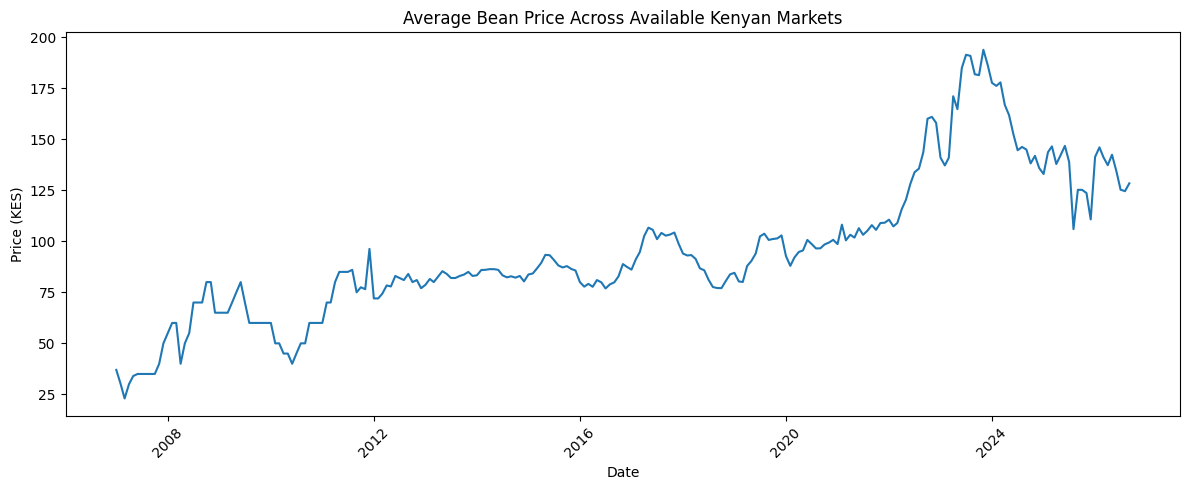

In [32]:
#Price over time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
beans_data["price_date"] = pd.to_datetime(beans_data["price_date"])
maize_data["price_date"] = pd.to_datetime(maize_data["price_date"])
#average price across available markets for each month
beans_monthly = (
    beans_data.groupby("price_date")["beans"]
    .mean()
    .reset_index())
maize_monthly = (
    maize_data.groupby("price_date")["maize_fao"]
    .mean()
    .reset_index())
# Plot beans
plt.figure(figsize=(12, 5))
plt.plot(beans_monthly["price_date"], beans_monthly["beans"])
plt.title("Average Bean Price Across Available Kenyan Markets")
plt.xlabel("Date")
plt.ylabel("Price (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

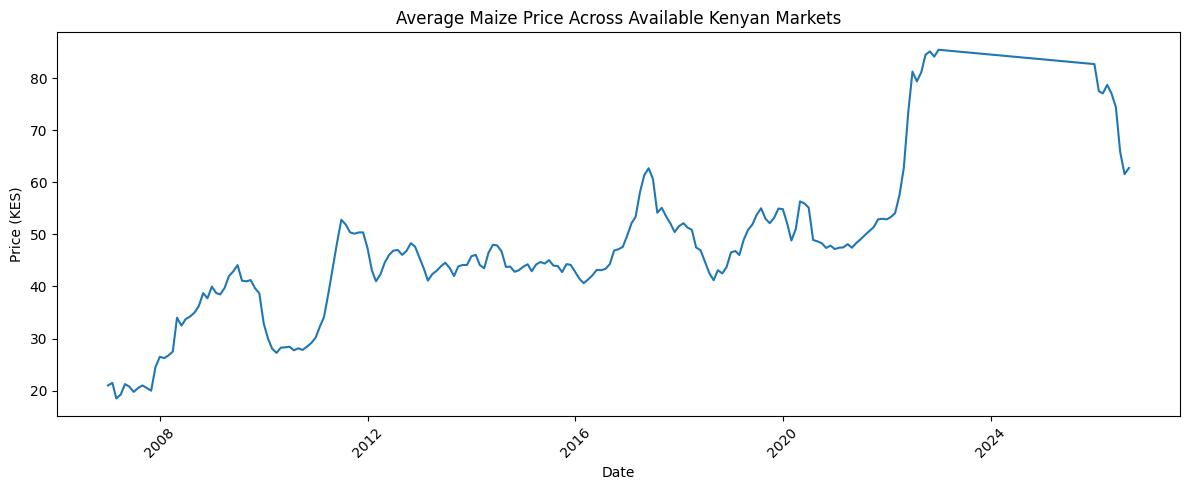

In [33]:
#maize chart
plt.figure(figsize=(12, 5))
plt.plot(maize_monthly["price_date"], maize_monthly["maize_fao"])
plt.title("Average Maize Price Across Available Kenyan Markets")
plt.xlabel("Date")
plt.ylabel("Price (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

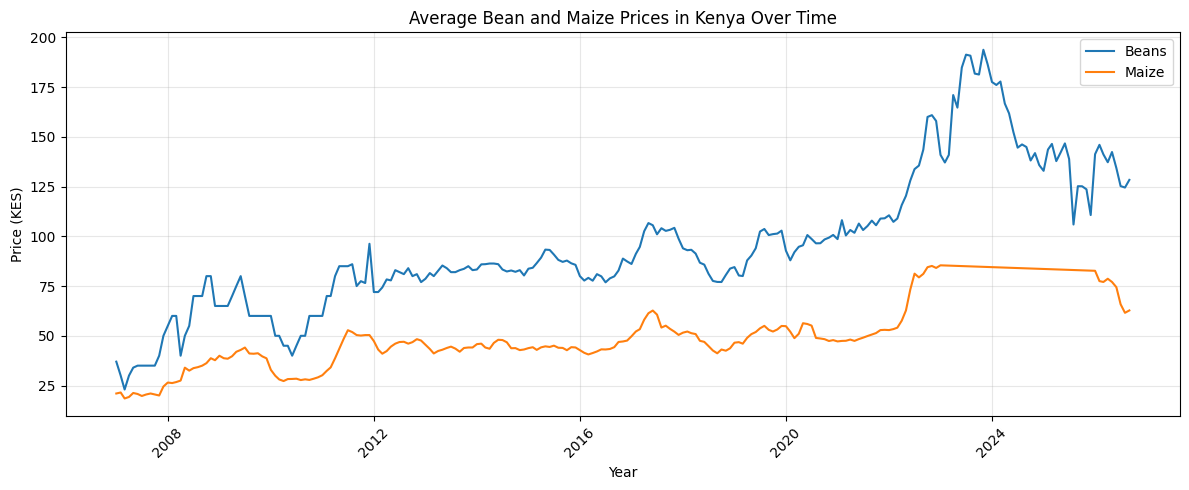

In [34]:
# Comparing average bean and maize prices over time

beans_monthly = beans_data.groupby("price_date")["beans"].mean()
maize_monthly = maize_data.groupby("price_date")["maize_fao"].mean()
plt.figure(figsize=(12, 5))
plt.plot(beans_monthly.index, beans_monthly.values, label="Beans")
plt.plot(maize_monthly.index, maize_monthly.values, label="Maize")
plt.title("Average Bean and Maize Prices in Kenya Over Time")
plt.xlabel("Year")
plt.ylabel("Price (KES)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Bean and Maize Prices Over Time

The graph shows how the average prices of beans and maize changed in Kenya over the years where both products show some fluctuations but bean prices are generally higher than maize prices..There is also a noticeable increase in prices around 2022 to 2024 especially for beans.

In [35]:
#averages prices by county
county_prices = food_prices.groupby("adm2_name")[price_columns].mean()
county_prices.head(10)

,beans,maize_fao,livestock_goat_s_fao
adm2_name,,,
Baringo,109.432597,45.962500,NaN
Chuka/Igambang'Ombe,NaN,38.748466,3336.576687
Garissa,129.286136,62.037815,2748.439759
Hola (Tana River),NaN,51.158472,NaN
Ijara,NaN,NaN,NaN
Isiolo,115.648333,50.900000,3092.337349
Kajiado,96.323000,51.083056,NaN
Kilifi,105.509846,43.396988,3088.417178
Kisumu,NaN,NaN,NaN


### Average Food Prices by County
I wanted to compare the average prices of the available food products across different counties in Kenya and this has helped to show how food prices vary from one area to another.

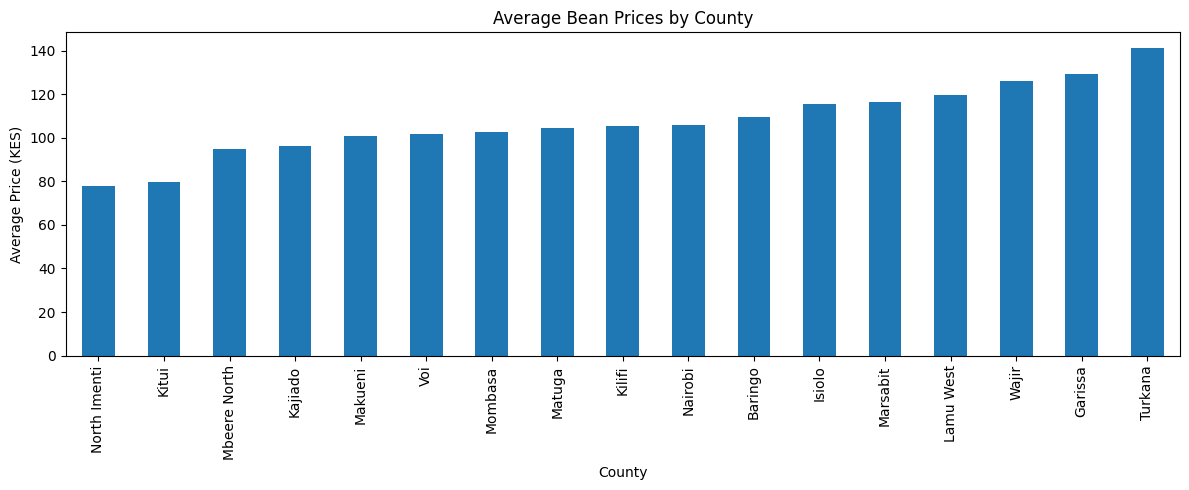

In [36]:
county_prices["beans"].dropna().sort_values().plot(kind="bar", figsize=(12,5))
plt.title("Average Bean Prices by County")
plt.xlabel("County")
plt.ylabel("Average Price (KES)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

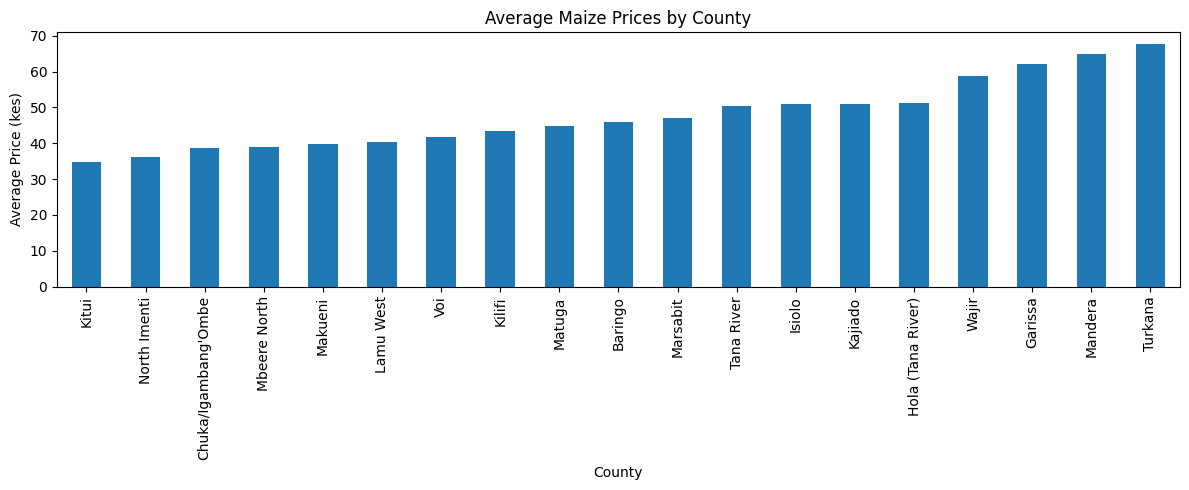

In [37]:
#maize prices by county
county_prices["maize_fao"].dropna().sort_values().plot(kind="bar", figsize=(12,5))
plt.title("Average Maize Prices by County")
plt.xlabel("County")
plt.ylabel("Average Price (kes)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Average Maize Prices by County

The graph shows differences in average maize prices across the counties...The variation suggests that maize prices are not the same across all areas of Kenya.

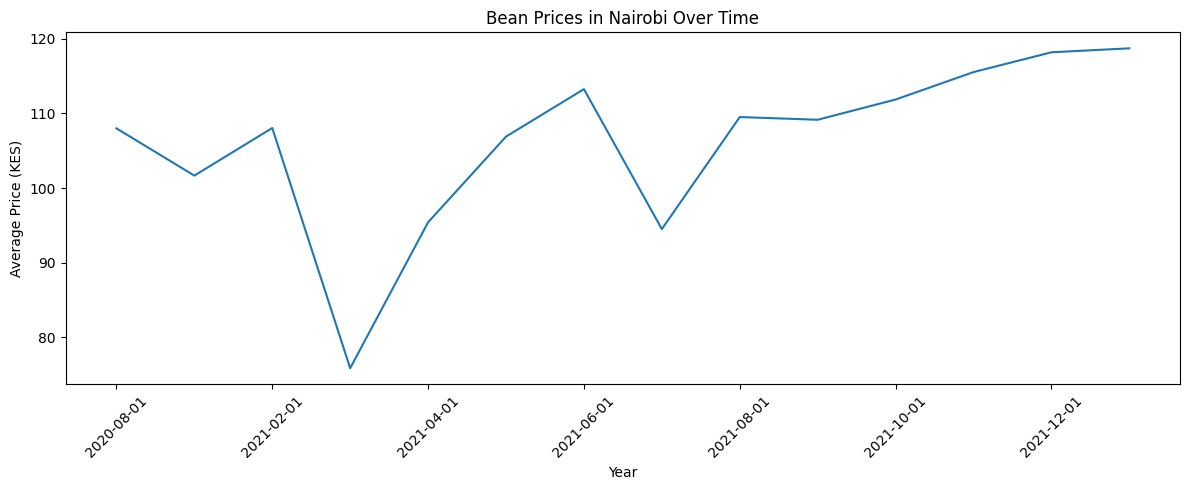

In [38]:
#how bean prices changed over time in different counties.
county = "Nairobi"
nairobi_beans = food_prices[(food_prices["adm2_name"] == county) &(food_prices["beans"].notna())]
nairobi_beans.groupby("price_date")["beans"].mean().plot(figsize=(12,5))
plt.title("Bean Prices in Nairobi Over Time")
plt.xlabel("Year")
plt.ylabel("Average Price (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Bean Prices in Nairobi Over Time
I looked at bean prices in Nairobi over time to see how the price changed across the period covered by the dataset.

In [39]:
#which counties have the highest and lowest average bean prices.
bean_county_prices = county_prices["beans"].dropna()
print("Lowest average bean prices:")
print(bean_county_prices.nsmallest(5))
print("\nHighest average bean prices:")
print(bean_county_prices.nlargest(5))

Lowest average bean prices:
adm2_name
North Imenti     78.066038
Kitui            79.631980
Mbeere North     94.893617
Kajiado          96.323000
Makueni         100.691489
Name: beans, dtype: float64

Highest average bean prices:
adm2_name
Turkana      141.382471
Garissa      129.286136
Wajir        126.154286
Lamu West    119.563830
Marsabit     116.377778
Name: beans, dtype: float64


### Highest and Lowest Bean Prices by County

I compared the average bean prices across counties to identify the areas with the lowest and highest average prices.

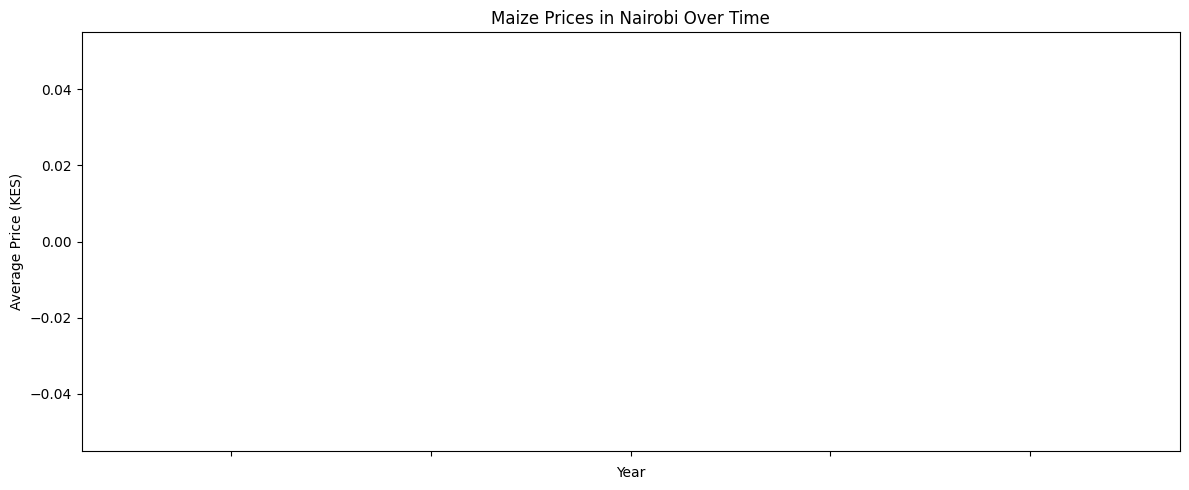

In [40]:
#maize prices over time in Nairobi.
nairobi_maize = food_prices[
    (food_prices["adm2_name"] == "Nairobi") &
    (food_prices["maize_fao"].notna())]
nairobi_maize.groupby("price_date")["maize_fao"].mean().plot(figsize=(12,5))
plt.title("Maize Prices in Nairobi Over Time")
plt.xlabel("Year")
plt.ylabel("Average Price (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
# Check missing values for the main food prices
food_prices[price_columns].isna().sum()

,0
beans,54087
maize_fao,52865
livestock_goat_s_fao,53309


### Missing Values in Food Prices

I checked the main food price columns for missing values before continuing with the analysis which helped me understand which products have enough data for further analysis.

****FEATURING ENGINEERING

In [44]:
# Create a copy for the modelling stage
model_data = food_prices.copy()
# Convert price_date to datetime
model_data["price_date"] = pd.to_datetime(model_data["price_date"])
# Create simple time features
model_data["year"] = model_data["price_date"].dt.year
model_data["month"] = model_data["price_date"].dt.month
model_data.head()

,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,price_date,year,...,l_maize_fao,c_maize_fao,inflation_maize_fao,trust_maize_fao,o_food_price_index,h_food_price_index,l_food_price_index,c_food_price_index,inflation_food_price_index,trust_food_price_index
0,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-01-01,2007,...,22.05,22.98,NaN,9.5,0.52,0.54,0.50,0.52,NaN,8.9
1,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-02-01,2007,...,22.19,22.26,NaN,9.5,0.52,0.54,0.50,0.51,NaN,8.9
2,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-03-01,2007,...,20.99,20.99,NaN,9.5,0.51,0.53,0.49,0.52,NaN,8.9
3,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-04-01,2007,...,20.08,20.08,NaN,9.5,0.52,0.54,0.50,0.51,NaN,8.9
4,KEN,Kenya,Coast,Tana River,Adele Center,-0.47,39.61,gid_-4700000396100000,2007-05-01,2007,...,19.22,19.22,NaN,9.5,0.51,0.53,0.49,0.49,NaN,8.9


In [46]:
# Create simple features for the model

model_data["avg_food_price"] = model_data[price_columns].mean(axis=1)
model_data["food_price_index"] = (
    model_data["avg_food_price"] / model_data["avg_food_price"].mean())
model_data["quarter"] = model_data["price_date"].dt.quarter
model_data[["price_date", "year", "month", "avg_food_price",
            "food_price_index", "quarter"]].head()

,price_date,year,month,avg_food_price,food_price_index,quarter
0,2007-01-01,2007,1,NaN,NaN,1
1,2007-02-01,2007,2,NaN,NaN,1
2,2007-03-01,2007,3,NaN,NaN,1
3,2007-04-01,2007,4,NaN,NaN,2
4,2007-05-01,2007,5,NaN,NaN,2


In [47]:
# cleaning the model..Keep rows where we have an average food price
model_data = model_data.dropna(subset=["avg_food_price"])
print("Rows available for modelling:", len(model_data))
model_data[["price_date", "adm2_name", "avg_food_price", "food_price_index"]].head()

Rows available for modelling: 3810


,price_date,adm2_name,avg_food_price,food_price_index
2558,2021-01-01,Mombasa,80.00,0.076512
2560,2021-03-01,Mombasa,100.00,0.095640
2561,2021-04-01,Mombasa,106.36,0.101723
2565,2021-08-01,Mombasa,111.33,0.106476
2566,2021-09-01,Mombasa,106.00,0.101379


In [48]:
#preoaring the model data
# Select the features and target
features = ["year", "month", "quarter", "lat", "lon", "adm2_name"]
target = "avg_food_price"
model_df = model_data[features + [target]].copy()
# Remove rows with missing values
model_df = model_df.dropna()
model_df.head()

,year,month,quarter,lat,lon,adm2_name,avg_food_price
2558,2021,1,1,-4.01,39.63,Mombasa,80.00
2560,2021,3,1,-4.01,39.63,Mombasa,100.00
2561,2021,4,2,-4.01,39.63,Mombasa,106.36
2565,2021,8,3,-4.01,39.63,Mombasa,111.33
2566,2021,9,3,-4.01,39.63,Mombasa,106.00


In [49]:
#split the data
# Sort the data by date
model_data = model_data.sort_values("price_date")
# Prepare features and target
X = model_df[features]
y = model_df[target]
# Use the first 80% for training and the last 20% for testing
split = int(len(model_df) * 0.8)
X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 3048
Testing rows: 762


In [54]:
# Random Forest model
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42)
rf_model.fit(X_train_enc, y_train_enc)
rf_pred = rf_model.predict(X_test_enc)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [55]:
# Evaluate the Random Forest model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
rf_mae = mean_absolute_error(y_test_enc, rf_pred)
rf_rmse = mean_squared_error(y_test_enc, rf_pred) ** 0.5
rf_r2 = r2_score(y_test_enc, rf_pred)
print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))
print("Random Forest R²:", round(rf_r2, 2))

Random Forest MAE: 274.25
Random Forest RMSE: 409.23
Random Forest R²: 0.64


### Random Forest Model Evaluation

The Random Forest model performed better than the Linear Regression better.. It achieved an R² score of 0.64 meaning that the model explains about 64% of the variation in average food prices.
The MAE was 274.25 and the RMSE was 409.23. These results show that the Random Forest model provides a more useful fit for predicting average food prices in this dataset.

In [56]:
# Check which features are most important in the Random Forest model
feature_importance = pd.DataFrame({
    "feature": X_train_enc.columns,
    "importance": rf_model.feature_importances_})
feature_importance = feature_importance.sort_values(
    by="importance", ascending=False)
feature_importance.head(10)

,feature,importance
4,lon,0.392942
0,year,0.280693
6,adm2_name_Garissa,0.094616
7,adm2_name_Hola (Tana River),0.073107
3,lat,0.060816
1,month,0.036056
18,adm2_name_Mombasa,0.015252
11,adm2_name_Kitui,0.011379
21,adm2_name_Tana River,0.008396
13,adm2_name_Makueni,0.007870


### Feature Importance

The Random Forest model was used to identify which features contributed most to predicting average food prices. Longitude and year were the most important features followed by some county level indicators such as Garissa and Hola (Tana River).


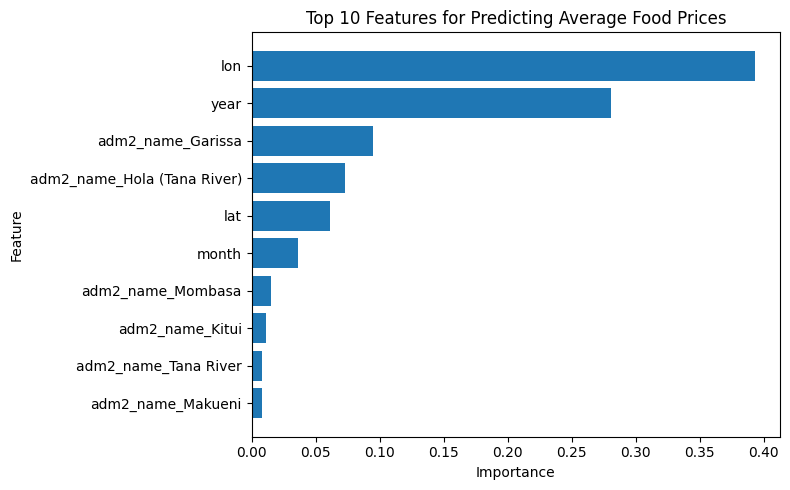

In [57]:
# Plot the top 10 most important features
top_features = feature_importance.head(10)
plt.figure(figsize=(8, 5))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features for Predicting Average Food Prices")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Feature Importance Interpretation

The feature importance plot shows that longitude and year were the two most influential features in the Random Forest model. Some county level features also contributed to the predictions while month had a smaller contribution..
This indicates that both location and time are important when predicting average food prices in Kenya.

In [58]:
# Compare model performance
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2": [r2, rf_r2]})
model_comparison

,Model,MAE,RMSE,R2
0,Linear Regression,2862.843422,4105.471344,-35.505845
1,Random Forest,274.248700,409.225319,0.637288


In [60]:
#hyperameter tuning
# Tune the Random Forest model
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None]}
rf_tuned = RandomForestRegressor(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf_tuned,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring="neg_mean_squared_error",
    random_state=42,
    n_jobs=-1)
random_search.fit(X_train_enc, y_train_enc)
print("Best parameters:")
print(random_search.best_params_)

Best parameters:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 10}


In [61]:
# Train the tuned Random Forest model using the best parameters
best_rf_model = random_search.best_estimator_
# Make predictions on the untouched test data
y_pred_tuned = best_rf_model.predict(X_test_enc)
print("Tuned Random Forest model trained successfully.")

Tuned Random Forest model trained successfully.


In [62]:
# Evaluate the tuned Random Forest model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
tuned_mae = mean_absolute_error(y_test_enc, y_pred_tuned)
tuned_rmse = mean_squared_error(y_test_enc, y_pred_tuned) ** 0.5
tuned_r2 = r2_score(y_test_enc, y_pred_tuned)
print("Tuned Random Forest MAE:", round(tuned_mae, 2))
print("Tuned Random Forest RMSE:", round(tuned_rmse, 2))
print("Tuned Random Forest R²:", round(tuned_r2, 2))

Tuned Random Forest MAE: 422.67
Tuned Random Forest RMSE: 581.44
Tuned Random Forest R²: 0.27


In [63]:
# Compare the original and tuned Random Forest models

comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Tuned Random Forest"],
    "MAE": [274.25, tuned_mae],
    "RMSE": [409.23, tuned_rmse],
    "R2": [0.64, tuned_r2]})
comparison

,Model,MAE,RMSE,R2
0,Original Random Forest,274.250000,409.23000,0.640000
1,Tuned Random Forest,422.672193,581.44013,0.267772


In [64]:
#model testing/error analysis
# Compare actual and predicted food prices

results = pd.DataFrame({
    "Actual_Price": y_test_enc,
    "Predicted_Price": y_pred})
results["Error"] = results["Actual_Price"] - results["Predicted_Price"]
results["Absolute_Error"] = abs(results["Error"])
results.head(10)

,Actual_Price,Predicted_Price,Error,Absolute_Error
39140,872.333333,1701.517105,-829.183772,829.183772
39141,1166.333333,1710.740121,-544.406788,544.406788
39142,1190.000000,1719.963137,-529.963137,529.963137
39143,1231.666667,1713.954721,-482.288054,482.288054
39144,1138.333333,1723.177737,-584.844404,584.844404
39145,1104.333333,1732.400753,-628.067420,628.067420
39146,1042.333333,1726.392337,-684.059003,684.059003
39147,1071.000000,1735.615353,-664.615353,664.615353
39148,1116.666667,1744.838369,-628.171702,628.171702
39149,972.000000,1758.093701,-786.093701,786.093701


## Model Evaluation and Selection

Two Random Forest Regression models were evaluated..the original Random Forest model and a tuned Random Forest model.
The original Random Forest performed better, achieving an R² score of 0.64, a Mean Absolute Error (MAE) of 274.25, and a Root Mean Squared Error (RMSE) of 409.23.
The tuned Random Forest performed worse, with an R² score of 0.27, an MAE of 422.67, and an RMSE of 581.44.
Based on both evaluation metrics the original Random forest model was selected as the final model because it explained more variation in average food prices and produced lower prediction errors.

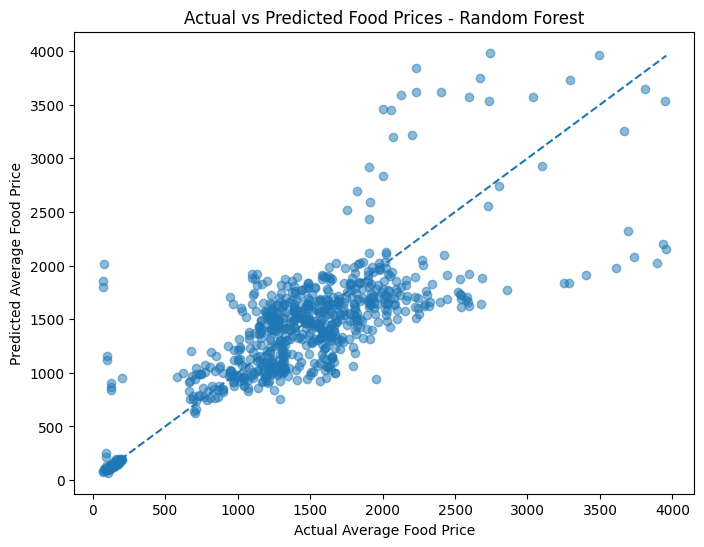

In [66]:
#final model visualization
#Actual vs Predicted Food Prices - Original Random Forest

import matplotlib.pyplot as plt

# Generate predictions using the original Random Forest model
y_pred = rf_model.predict(X_test_enc)
plt.figure(figsize=(8, 6))
plt.scatter(y_test_enc, y_pred, alpha=0.5)

# Perfect prediction line
plt.plot(
    [y_test_enc.min(), y_test_enc.max()],
    [y_test_enc.min(), y_test_enc.max()],
    linestyle="--")
plt.xlabel("Actual Average Food Price")
plt.ylabel("Predicted Average Food Price")
plt.title("Actual vs Predicted Food Prices - Random Forest")

plt.show()

## Actual vs Predicted Food Prices

The scatter plot compares the actual average food prices with the prices predicted by the Random Forest model. The dashed line represents perfect predictions where the predicted price would exactly match the actual price.
Most observations show a positive relationship between actual and predicted prices indicating that the model is able to capture important patterns in food prices...

## Key Findings from the Model

The Random Forest model identified several important factors associated with average food prices.
The most important features were:
- **Longitude (lon)** – the strongest predictor in the model.
- **Year** – indicating that food prices vary over time.
- **County/location** – including Garissa, Hola (Tana River), Mombasa, Kitui, Tana River, and Makueni.
- **Latitude (lat)** – suggesting that geographic location also contributes to differences in food prices.
- **Month** – indicating some variation in food prices across different months.
These results suggest that food prices in Kenya are influenced by a combination of **geographic location and time**.

# Conclusion
This analysis examined food prices in Kenya and explored how food affordability varies across different locations and periods.
The analysis showed that average food prices differ considerably across counties and over time. Geographic variables like longitude, latitude and county were important in explaining differences in food prices..The year and month also contributed to the variation observed in food prices.
The Random Forest model achieved an R² score of **0.64** showing that it was able to explain a substantial portion of the variation in average food prices...